<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 50px;">Projeto 1 - LabIACD</div>
<div style="text-align: center; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 26px;">Notebook 3 de 3: segmentação otimizada</div>

 Esta notebook mantém o mesmo processo geral (máscara do nódulo, features do pyradiomics, pré-processamento, modelos e conversão das previsões em notas), mas muda quatro pontos. O primeiro é a label: a competição avalia a média arredondada das notas dos radiologistas, e não a mediana usada até aqui (9.1). O segundo é a região de onde se extraem as features: em vez de uma esfera fixa de 7 mm, que não acompanha o nódulo, o nódulo é segmentado em cada cubo (9.2 e 9.3). O terceiro são as features: as mesmas cerca de 1130 do pyradiomics, agora calculadas na máscara do nódulo, mais 16 complementares (9.4). O quarto é a forma de decidir: os limiares que convertem as previsões em notas passam a ser aprendidos apenas no LNDb, e as escolhas são poucas e feitas com uma regra que evita perseguir o ruído (10 e 11).

No fim, o modelo escolhido é avaliado no holdout e gera o `predictions.csv` (12), e a secção 13 analisa os resultados com gráficos. Este notebook corre depois das secções 2 a 4 do notebook 1, que criam os ficheiros em `data/`, e usa `configuracao.py`, `comum.py` e `graficos.py`. O holdout é o mesmo do notebook 1.

In [2]:
# Importações e threads (configuracao.py, tem de vir primeiro) e ferramentas partilhadas (comum.py)
from configuracao import *
from comum import *
import graficos as G                           # tabelas compactas e gráficos (secção 13)
from itertools import combinations

# Pasta do LNDb (CTs e máscaras dos radiologistas), a mesma do notebook 1
LNDB = Path("LNDb")
DADOS = Path("data")
SEEDS_V2 = [0, 1, 2, 3, 4]                     # 5 repetições da validação cruzada
CUBOS = {n: np.load(DADOS / f, mmap_mode="r") for n, f in
         [("LIDC", "patches.npy"), ("LNDb", "patches_lndb.npy"), ("teste", "patches_teste.npy")]}

c:\Users\Guilherme\.conda\envs\radiomica\Lib\site-packages\pylidc\__init__.py:27: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources as _pr


Desenvolvimento: 2893 nódulos | holdout (LNDb): 72


<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">9. Label, segmentação e features</div>
<br>

Esta secção prepara tudo aquilo de que os modelos precisam: a label de cada nódulo, a máscara do nódulo em cada cubo e as features extraídas dessa máscara. A extração é o passo mais demorado do notebook, por isso os resultados ficam guardados em `data/` e só são calculados uma vez.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">9.1 Label: média das notas</div>

No notebook 1, a label de cada nódulo era a mediana das notas dos radiologistas. A competição, porém, avalia a média das notas arredondada, e as duas podem ser diferentes. Por isso, os modelos passam a aprender a **média contínua** das notas, que tem também mais informação do que uma nota inteira (um nódulo com média 2,0 e outro com 2,4 não são iguais), e a classe usada nas métricas é a média arredondada. A célula mostra quantas labels mudam com esta alteração.

In [3]:
ARREDONDAMENTO = "meio_para_cima"


def arredondar_nota(media):
    """Média contínua → nota de 1 a 5."""
    media = np.asarray(media, dtype=float)
    return np.clip(np.floor(media + 0.5) if ARREDONDAMENTO == "meio_para_cima" else np.round(media), 1, 5).astype(int)


# T2: uma linha por nódulo de df_total (mesma ordem), com as notas de cada radiologista
nod_lidc = pd.read_csv(DADOS / "nodulos.csv")
cub_lndb = pd.read_csv(DADOS / "lndb_cubos.csv").set_index("idx")
e_lidc_t, idx_t = (df_total["dataset"] == "LIDC").to_numpy(), df_total["idx"].to_numpy()
notas = np.empty(len(df_total), dtype=object)
notas[e_lidc_t] = [ler_notas(v) for v in nod_lidc["malig_notas"].iloc[idx_t[e_lidc_t]]]
notas[~e_lidc_t] = [ler_notas(v) for v in cub_lndb.loc[idx_t[~e_lidc_t], "malig_notas"]]

T2 = df_total[["dataset", "idx", "patient"]].copy()
T2["notas"] = [[n for n in v if n > 0] for v in notas]
T2["alvo"] = T2["notas"].apply(np.mean)                                 # alvo contínuo dos modelos
T2["classe"] = arredondar_nota(T2["alvo"])                              # label da competição
# Diâmetro dos radiologistas: só para validar a segmentação (9.4), nunca como feature
T2["diam_radiologistas"] = np.where(e_lidc_t, nod_lidc["diameter"].reindex(idx_t).to_numpy(),
                                    (6 * cub_lndb["Volume"].reindex(idx_t).to_numpy() / np.pi) ** (1 / 3))
E2, DEV2 = (T2["dataset"] == "LNDb").to_numpy(), ~e_holdout
mudam = T2["classe"] != df_total["classe"].to_numpy()
print(f"Labels que mudam da mediana para a média: LNDb {mudam[E2].mean():.1%} | LIDC {mudam[~E2].mean():.1%}")

Labels que mudam da mediana para a média: LNDb 1.4% | LIDC 9.5%


> Resultado: só 1,4% das labels do LNDb mudam, ou seja, apenas alguns nódulos. A mediana e a média só diferem quando há três notas distribuídas de forma assimétrica (por exemplo, 1, 1 e 4), o que é raro no LNDb. O efeito da mudança de label nas métricas é, por isso, quase nulo, e a principal vantagem desta secção é o alvo contínuo.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">9.2 Segmentação do nódulo</div>

A esfera fixa da primeira versão não acompanha o nódulo. Num nódulo pequeno apanha também vasos e parede, num grande apanha só o centro, e o volume nunca passa do volume da esfera, apesar de o tamanho ser o fator mais ligado à malignidade. Nesta versão, o nódulo é segmentado em cada cubo com um método clássico, sem aprendizagem, porque no teste só se conhece a posição de cada lesão.

A segmentação começa por escolher um **limiar adaptado a cada nódulo**, a meio caminho entre a densidade do seu centro (percentil 75 de um cubo de 6 mm) e a do pulmão (−850 HU), limitado a [−750, −400] HU. Assim, um nódulo sólido (cerca de 0 HU) fica com um limiar de cerca de −425 HU, e um em vidro despolido (cerca de −500 HU) com cerca de −675 HU. Os voxels acima do limiar têm as **cavidades preenchidas**, e fica apenas a **região ligada ao centro** do cubo. Depois, uma **abertura morfológica** com uma bola de metade do raio do nódulo separa os vasos mais finos do que ele, um **limite à volta do centro** (1,25 vezes o raio mais 2 mm) corta a parede torácica, e uma dilatação dentro da máscara original **recupera a borda** do nódulo. Se nada denso tocar no centro, usa-se uma esfera de 5 mm, e esse recurso fica registado como feature.

In [4]:
_g = np.indices((48, 48, 48)).astype(np.float32) - 23.5
R_CENTRO = np.sqrt((_g ** 2).sum(0))                 # distância (mm) de cada voxel ao centro do cubo
ESFERA_20 = R_CENTRO <= 20                           # a segmentação nunca sai de uma esfera de 20 mm
ESFERA_PEQ = R_CENTRO <= 5                           # recurso: esfera de 5 mm
del _g


def bola(r):
    """Elemento estruturante esférico de raio r (voxels)."""
    z, y_, x = np.mgrid[-r:r + 1, -r:r + 1, -r:r + 1]
    return (x ** 2 + y_ ** 2 + z ** 2) <= r ** 2


def componente_do_centro(m, raio_max=3):
    """Componente ligada que contém o voxel de m mais próximo do centro (a no máximo raio_max mm)."""
    if not m.any():
        return None
    d = np.where(m, R_CENTRO, np.inf)
    v = np.unravel_index(np.argmin(d), d.shape)
    if d[v] > raio_max:
        return None
    rotulos, _ = ndi.label(m)
    return rotulos == rotulos[v]


def limiar_adaptativo(cubo, i_pulmao=-850):
    """Meio caminho entre a densidade do centro do nódulo e a do pulmão, entre -750 e -400 HU."""
    i_nodulo = np.percentile(cubo[21:27, 21:27, 21:27], 75)
    return float(np.clip((i_nodulo + i_pulmao) / 2, -750, -400))


def segmentar(cubo):
    """Máscara do nódulo no centro do cubo. Devolve (máscara, limiar usado ou None se recorreu à esfera de 5 mm)."""
    cubo = np.asarray(cubo, dtype=np.float32)
    limiar = limiar_adaptativo(cubo)
    m = ndi.binary_fill_holes((cubo > limiar) & ESFERA_20)            # 1-2: limiar e cavidades
    m = componente_do_centro(m)                                         # 3: componente do centro
    if m is None:
        return ESFERA_PEQ.copy(), None
    r0 = max(ndi.distance_transform_edt(m)[21:27, 21:27, 21:27].max(), 1.0)   # raio do nódulo
    k = max(1, int(round(0.5 * r0)))                                    # 4: abertura de meio raio
    nucleo = componente_do_centro(ndi.binary_opening(m, structure=bola(k)), raio_max=r0)
    if nucleo is None:
        nucleo = m & (R_CENTRO <= r0)
    limite = R_CENTRO <= 1.25 * r0 + 2                                  # 5: limite e reconstrução da borda
    final = ndi.binary_dilation(nucleo & limite, iterations=k, mask=m & limite)
    if final.sum() < 10:
        return ESFERA_PEQ.copy(), None
    return final, limiar

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">9.3 Validação da segmentação: Dice com os radiologistas (LNDb)</div>

Antes de extrair features da segmentação, convém confirmar que ela corresponde de facto ao nódulo. No LNDb, os radiologistas desenharam a máscara de cada nódulo que marcaram, o que permite essa verificação. Cada máscara (`LNDb-XXXX_radY.mhd`) é recortada exatamente como o cubo do CT e comparada com a segmentação e com a esfera da primeira versão (raio de 7 mm, acima de −600 HU) pelo **coeficiente de Dice**, 2|A∩B| / (|A| + |B|), que vale 1 quando as duas máscaras coincidem e 0 quando não se tocam. Como nem os radiologistas desenham o mesmo contorno, a referência realista é o Dice **entre radiologistas**. As máscaras dos radiologistas servem apenas para esta avaliação e nunca para extrair features, porque não existem no teste. A figura mostra dois nódulos de cada faixa de tamanho, para se ver onde a segmentação acerta e onde falha.

In [5]:
print(LNDB, LNDB.exists())

LNDb True


,segmentação v3,esfera (1.ª versão),entre radiologistas,n
< 5 mm,0.55,0.27,0.66,183
5–8 mm,0.68,0.50,0.74,120
8–12 mm,0.69,0.71,0.82,29
≥ 12 mm,0.67,0.66,0.86,26
total,0.62,0.41,0.73,358


Falhas graves (Dice < 0,2): segmentação 13% | esfera 26%


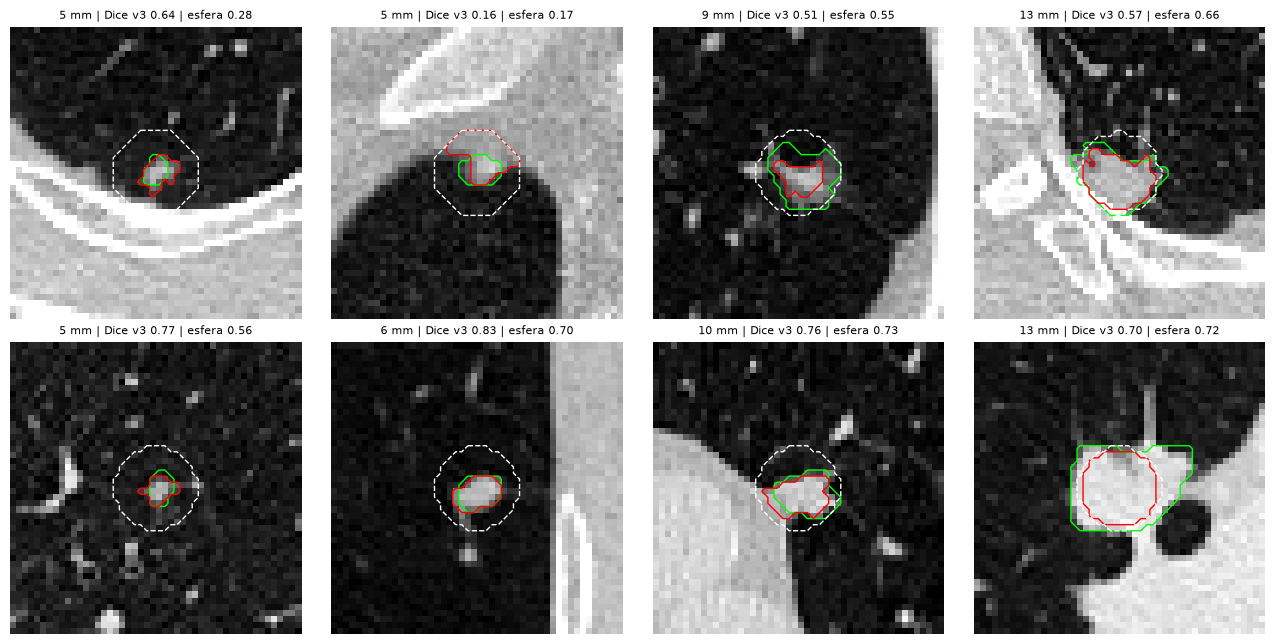

In [6]:
def dice(a, b):
    s = a.sum() + b.sum()
    return 2 * (a & b).sum() / s if s else np.nan


def mm_para_voxel(img, xyz_mm):
    """Posição em mm → índices (linha, coluna, corte), como no notebook 1 (2.3)."""
    ix, iy, iz = img.TransformPhysicalPointToContinuousIndex(tuple(float(v) for v in xyz_mm))
    return np.round([iy, ix, iz]).astype(int)


def carregar_mascara(caminho, lado_mm=48):
    """Máscara de um radiologista na ordem (linha, coluna, corte), com margem para o recorte."""
    img = sitk.ReadImage(str(caminho))
    arr = sitk.GetArrayFromImage(img).transpose(1, 2, 0)
    sx, sy, sz = img.GetSpacing()
    hv = np.ceil(lado_mm / 2 / np.array([sy, sx, sz])).astype(int)
    return img, np.pad(arr.astype(np.int16), [(x, x) for x in hv]), hv


def recortar_mascara(img, arr, hv, finding, xyz, lado_mm=48):
    """Recorta a máscara de um achado exatamente como o cubo do CT (mesmo centro, 48 mm, 1 mm)."""
    c = mm_para_voxel(img, xyz)
    rec = arr[c[0]:c[0] + 2 * hv[0], c[1]:c[1] + 2 * hv[1], c[2]:c[2] + 2 * hv[2]] == finding
    return zoom(rec.astype(np.float32), lado_mm / np.array(rec.shape), order=1) >= 0.5


def mascaras_radiologistas(n, ficheiros, cache):
    """Máscaras dos radiologistas que marcaram o nódulo n (uma linha de lndb_cubos.csv)."""
    res = []
    for r, f in zip(str(n.RadID).split(","), str(n.RadFindingID).split(",")):
        nome = f"LNDb-{int(n.LNDbID):04d}_rad{int(float(r))}"
        if nome in ficheiros:
            if nome not in cache:
                cache[nome] = carregar_mascara(ficheiros[nome])
            m = recortar_mascara(*cache[nome], int(float(f)), (n.x, n.y, n.z))
            if m.any():
                res.append(m)
    return res


ESFERA_V1 = R_CENTRO <= RAIO_ESFERA                                     # região da primeira versão
ficheiros_mask = {p.stem: p for p in LNDB.rglob("LNDb-*_rad*.mhd")}
linhas, RAD = [], {}
for lndb_id, grupo in pd.read_csv(DADOS / "lndb_cubos.csv").groupby("LNDbID"):
    cache = {}                                                          # máscaras deste CT, lidas uma vez
    for n in grupo.itertuples():
        rads = mascaras_radiologistas(n, ficheiros_mask, cache)
        if not rads:
            continue
        RAD[n.idx] = rads
        cubo = np.asarray(CUBOS["LNDb"][n.idx], dtype=np.float32)
        seg, esf = segmentar(cubo)[0], ESFERA_V1 & (cubo > -600)
        pares = [dice(a, b) for a, b in combinations(rads, 2)]
        linhas.append({"idx": n.idx, "diam_rad": (6 * np.mean([m.sum() for m in rads]) / np.pi) ** (1 / 3),
                       "segmentação v3": np.mean([dice(seg, m) for m in rads]),
                       "esfera (1.ª versão)": np.mean([dice(esf, m) for m in rads]),
                       "entre radiologistas": np.mean(pares) if pares else np.nan})
DICE = pd.DataFrame(linhas)
DICE["tamanho"] = pd.cut(DICE["diam_rad"], [0, 5, 8, 12, 100], labels=["< 5 mm", "5–8 mm", "8–12 mm", "≥ 12 mm"])
cols_d = ["segmentação v3", "esfera (1.ª versão)", "entre radiologistas"]
TAB_DICE = pd.concat([DICE.groupby("tamanho", observed=True)[cols_d].median(),
                      DICE[cols_d].median().to_frame("total").T]).assign(
    n=list(DICE.groupby("tamanho", observed=True).size()) + [len(DICE)])
G.mostrar(G.tabela_compacta(TAB_DICE, "Dice mediano por tamanho do nódulo (a roxo: o melhor método em cada linha)",
                            casas=2, cores=cols_d, por_linha=True))
print(f"Falhas graves (Dice < 0,2): segmentação {(DICE['segmentação v3'] < 0.2).mean():.0%} | "
      f"esfera {(DICE['esfera (1.ª versão)'] < 0.2).mean():.0%}")

# Verificação visual: dois nódulos por faixa de tamanho
# (verde: radiologistas; vermelho: segmentação v3; branco a tracejado: esfera da 1.ª versão)
escolhidos = DICE.groupby("tamanho", observed=True, group_keys=False).apply(lambda g: g.sample(min(2, len(g)), random_state=0))
fig, axes = plt.subplots(2, 4, figsize=(13, 6.5))
for ax, (_, r) in zip(axes.T.flat, escolhidos.iterrows()):
    i = int(r["idx"])
    cubo = np.asarray(CUBOS["LNDb"][i], dtype=np.float32)
    seg, rad = segmentar(cubo)[0], np.mean(RAD[i], axis=0) >= 0.5
    z = int(np.argmax(rad.sum(axis=(0, 1))))                            # corte com mais área dos radiologistas
    ax.imshow(np.clip(cubo[:, :, z], -1000, 400), cmap="gray")
    for m, cor, ls in [(rad, "lime", "-"), (seg, "red", "-"), (ESFERA_V1, "white", "--")]:
        if m[:, :, z].any():
            ax.contour(m[:, :, z], levels=[0.5], colors=cor, linewidths=1, linestyles=ls)
    ax.set_title(f"{r['diam_rad']:.0f} mm | Dice v3 {r['segmentação v3']:.2f} | esfera {r['esfera (1.ª versão)']:.2f}", fontsize=8)
    ax.axis("off")
for ax in axes.flat[len(escolhidos):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

> **Resultado**: a segmentação acompanha o nódulo muito melhor do que a esfera da primeira versão. O Dice mediano é de 0,62, contra 0,41 da esfera, perto do valor entre radiologistas (0,73), e as falhas graves baixam de 26% para 13%. O ganho é maior nos nódulos com menos de 5 mm, que são a maioria (0,55 contra 0,27), e continua claro entre 5 e 8 mm (0,68 contra 0,50). Nos nódulos acima de 8 mm, a esfera empata (0,71 contra 0,69 entre 8 e 12 mm, e 0,66 contra 0,67 a partir de 12 mm) e a segmentação fica mais longe dos radiologistas, mas estas faixas têm poucos nódulos.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">9.4 Features: pyradiomics na máscara do nódulo + complementares</div>

Com a máscara definida, extraem-se as mesmas features do pyradiomics da secção 3 do notebook 1: 7 classes (forma, primeira ordem, GLCM, GLRLM, GLSZM, GLDM e NGTDM), na imagem original, em três filtros LoG (σ = 1, 2 e 3 mm) e em 8 wavelets, com `binWidth = 25`, num total de **cerca de 1130 features**. Como a configuração é igual, a diferença em relação à primeira versão está apenas na região de onde as features são calculadas.

A estas juntam-se **16 features complementares**, que o pyradiomics não calcula e que descrevem sinais conhecidos de malignidade ou benignidade: o diâmetro axial (como o do `pylidc`), as frações sólida, em vidro despolido e **calcificada** (um sinal de benignidade), a fração de espículas, um anel de 2 mm à volta do nódulo (halo), a nitidez da margem e um **perfil radial calculado sem segmentação**, que dá informação mesmo quando a segmentação falha. O limiar usado e o indicador de recurso também entram como features. A extração corre em paralelo e é guardada em `data/features_v3_<conjunto>.csv`, retomando onde parou se for interrompida. No fim, compara-se o diâmetro segmentado com o anotado pelos radiologistas.

In [7]:
def _diametro_max(pts):
    """Maior distância entre dois pontos (calculada nos vértices do invólucro convexo)."""
    if len(pts) < 2:
        return 0.0
    try:
        if len(pts) > 3:
            pts = pts[ConvexHull(pts).vertices]
    except Exception:
        pass
    if len(pts) > 2000:                              # invólucro falhou num conjunto grande: subamostra
        pts = pts[np.random.default_rng(0).choice(len(pts), 2000, replace=False)]
    return float(np.sqrt(((pts[:, None] - pts[None]) ** 2).sum(-1)).max())


def complementares(cubo, m, limiar):
    """16 features que o pyradiomics não calcula."""
    f = {"seg_limiar": -1000.0 if limiar is None else limiar, "seg_recurso": float(limiar is None)}
    sup = m & ~ndi.binary_erosion(m)
    f["diam_axial"] = max([_diametro_max(np.argwhere(sup[:, :, z]).astype(float)) for z in range(48)
                           if sup[:, :, z].any()] or [0.0]) + 1        # maior diâmetro num corte axial
    v = cubo[m]
    f["frac_solido"], f["frac_vidro"] = (v > -300).mean(), ((v > -750) & (v <= -300)).mean()
    f["frac_calc"] = (v > 200).mean()
    for k in (1, 2):                                                    # volume que uma abertura de k mm retira
        f[f"frac_espiculas_{k}"] = 1 - ndi.binary_opening(m, bola(k)).sum() / max(m.sum(), 1)
    a = cubo[ndi.binary_dilation(m, bola(2)) & ~m]                      # anel de 2 mm à volta
    f["anel_hu_media"], f["anel_frac_vidro"] = a.mean(), ((a > -750) & (a <= -300)).mean()
    f["margem_nitidez"] = ndi.gaussian_gradient_magnitude(cubo, 1.0)[sup].mean() / max(v.mean() - a.mean(), 1.0)
    suave = ndi.gaussian_filter(cubo, 0.7)
    for r in (2, 4, 6, 10, 15):                                         # perfil radial, sem segmentação
        f[f"perfil_denso_r{r}"] = (suave[R_CENTRO <= r] > -600).mean()
    return f


def features_cubo(cubo):
    """Segmentação v3 + pyradiomics (~1130) + complementares (16) de um cubo 48³ (1 mm)."""
    logging.getLogger("radiomics").setLevel(logging.ERROR)
    cubo = np.asarray(cubo, dtype=np.float32)
    m, limiar = segmentar(cubo)
    ext = featureextractor.RadiomicsFeatureExtractor(binWidth=25)
    ext.disableAllFeatures()
    for classe in ["shape", "firstorder", "glcm", "glrlm", "glszm", "gldm", "ngtdm"]:
        ext.enableFeatureClassByName(classe)
    ext.enableImageTypes(Original={}, LoG={"sigma": [1.0, 2.0, 3.0]}, Wavelet={})
    img = sitk.GetImageFromArray(cubo); img.SetSpacing((1, 1, 1))
    msk = sitk.GetImageFromArray(m.astype(np.uint8)); msk.SetSpacing((1, 1, 1))
    try:
        f = {k: float(np.real(v)) for k, v in ext.execute(img, msk).items() if not k.startswith("diagnostics")}
    except Exception:
        f = {}                                                          # falha: NaN (preenchidos no pré-processamento)
    f.update(complementares(cubo, m, limiar))
    return f


def extrair_v3(nome, cubos, lote=100):
    """Features de todos os cubos de um conjunto, em paralelo, guardadas a cada lote (retoma onde parou)."""
    caminho = DADOS / f"features_v3_{nome}.csv"
    feito = pd.read_csv(caminho) if caminho.exists() else pd.DataFrame()
    for a in range(len(feito), len(cubos), lote):
        idxs = range(a, min(a + lote, len(cubos)))
        linhas = Parallel(n_jobs=N_JOBS)(delayed(features_cubo)(np.asarray(cubos[i])) for i in idxs)
        feito = pd.concat([feito, pd.DataFrame(linhas).assign(idx=list(idxs))], ignore_index=True)
        feito.to_csv(caminho, index=False)
        print(f"  {nome}: {len(feito)}/{len(cubos)}")
    return feito.set_index("idx").sort_index()


FEATS = {n: extrair_v3(n, c) for n, c in CUBOS.items()}
# F2: features na ordem de T2; F2_TESTE: linha i = cubo i do teste
F2 = pd.concat([FEATS[n].loc[t["idx"].to_numpy()].set_axis(t.index) for n, t in T2.groupby("dataset")]).loc[T2.index]
F2_TESTE = FEATS["teste"][F2.columns]
COLS_V3 = list(F2.columns)
print(f"{len(COLS_V3)} features | recurso (esfera de 5 mm): treino {F2['seg_recurso'].mean():.1%}, "
      f"teste {F2_TESTE['seg_recurso'].mean():.1%} | valores em falta: {int(F2.isna().sum().sum())}")
# Diâmetro segmentado vs. radiologistas (LIDC: axial, como o pylidc; LNDb: esfera com o mesmo volume)
d_seg = pd.Series(np.where(~E2, F2["diam_axial"], (6 * F2["original_shape_VoxelVolume"] / np.pi) ** (1 / 3)), index=T2.index)
for nome, msk in [("LIDC", ~E2), ("LNDb", E2)]:
    print(f"{nome}: Spearman diâmetro segmentado × radiologistas = "
          f"{stats.spearmanr(d_seg[msk], T2.loc[msk, 'diam_radiologistas'])[0]:.2f} | "
          f"× nota = {stats.spearmanr(d_seg[msk], T2.loc[msk, 'alvo'])[0]:.2f}")

1146 features | recurso (esfera de 5 mm): treino 1.2%, teste 0.4% | valores em falta: 0
LIDC: Spearman diâmetro segmentado × radiologistas = 0.62 | × nota = 0.33
LNDb: Spearman diâmetro segmentado × radiologistas = 0.56 | × nota = 0.24


> **Resultado**: foram extraídas 1146 features (cerca de 1130 do pyradiomics e 16 complementares), sem valores em falta. A esfera de recurso só foi usada em 1,2% dos nódulos de treino e em 0,4% das lesões do teste, por isso a segmentação encontrou tecido denso no centro em quase todos os casos. O diâmetro segmentado acompanha moderadamente o dos radiologistas (Spearman de 0,62 no LIDC e de 0,56 no LNDb), e a correlação com a nota (entre 0,24 e 0,33) confirma que o tamanho, sozinho, é informativo, mas está longe de chegar para prever a malignidade.

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">10. Pré-processamento e protocolo de avaliação</div>
<br>

Com as features prontas, falta definir como os modelos são treinados e comparados. O **pré-processamento** é o mesmo do notebook 1 (função da secção 5.1, em `comum.py`): imputação pela mediana do treino, remoção das features quase constantes e das redundantes (|Spearman| > 0,90) e normalização, tudo aprendido dentro de cada fold. Na 11.3, a seleção é comparada com a opção de usar todas as features, como na 6.6 do notebook 1. Todos os modelos são **regressores da média contínua**, avaliados com validação cruzada de 5 folds repetida 5 vezes, sempre com os pacientes separados.

A principal diferença está na conversão das previsões em notas. Os **limiares** são aprendidos **só nos nódulos do LNDb**, em validação aninhada: os nódulos do LNDb do desenvolvimento dividem-se em 5 partes por paciente, e os 4 limiares aprendem-se em 4 partes e aplicam-se à quinta. Os limiares maximizam **S = bal. acc. + macro F1 + QWK − MAE**, que junta as quatro métricas da competição, e comparam-se três formas de os obter: `otimizados`, `quantis` (reproduzem a proporção de cada nota no LNDb) e `arredondar`. Cada nódulo de treino recebe um **peso**, calculado só com o treino de cada fold: o peso do LNDb vezes o equilíbrio das classes elevado a `equilibrar`.

Para não escolher opções que só parecem melhores por acaso, todas as decisões seguem a **regra de um desvio**, fixada antes de ver os resultados: as opções a menos de um desvio (entre repetições) da melhor contam como empatadas, e fica a mais simples. Pela mesma razão, os modelos (LightGBM, CatBoost, Extra Trees, SVR e Ridge) usam **hiperparâmetros conservadores fixados à partida**, porque uma pesquisa extensa acrescentaria mais otimismo do que desempenho.

In [8]:
# ---- Dados do desenvolvimento e partições ----
IDX_D = T2.index[DEV2]
D2 = T2.loc[IDX_D]
ALVO_D, Y_D, G_D, E_D = D2["alvo"].to_numpy(), D2["classe"].to_numpy(), D2["patient"].to_numpy(), (D2["dataset"] == "LNDb").to_numpy()
PARTICOES = {s: list(StratifiedGroupKFold(5, shuffle=True, random_state=s).split(
                 D2, (D2["dataset"] + "_" + D2["classe"].astype(str)).to_numpy(), G_D)) for s in SEEDS_V2}
Y_L, G_L = Y_D[E_D], G_D[E_D]                                           # LNDb do desenvolvimento
PARTICOES_LNDB = {s: list(StratifiedGroupKFold(5, shuffle=True, random_state=100 + s).split(np.zeros(len(Y_L)), Y_L, G_L))
                  for s in SEEDS_V2}


def metricas_s(y_, p):
    m = metricas(y_, p)
    return {**m, "S": m["bal_acc"] + m["macro_f1"] + m["qwk"] - m["mae"]}


def score_s(y_, p):
    b, f, q, m = metricas_rapidas(y_, p)                               # comum.py: mesmas métricas, mais rápido
    return b + f + q - m


# ---- Limiares: contínuo → nota ----
def limiares_quantis(s, y_):
    """Limiares que reproduzem a proporção de cada nota."""
    acum = np.cumsum(np.bincount(y_, minlength=6)[1:] / len(y_))[:4]
    return np.quantile(s, np.clip(acum, 0.001, 0.999))


def otimizar_limiares_s(s, y_, n_cand=100, voltas=3):
    """4 limiares que maximizam S, mexendo um de cada vez (a partir dos quantis)."""
    cand = np.unique(np.quantile(s, np.linspace(0.003, 0.997, n_cand)))
    lim = np.sort(limiares_quantis(s, y_))
    melhor = score_s(y_, aplicar_limiares(s, lim))
    for _ in range(voltas):
        for k in range(4):
            lo, hi = (lim[k - 1] if k else -np.inf), (lim[k + 1] if k < 3 else np.inf)
            for t in cand[(cand > lo) & (cand < hi)]:
                novo = lim.copy(); novo[k] = t
                v = score_s(y_, aplicar_limiares(s, novo))
                if v > melhor:
                    melhor, lim = v, novo
    return lim


def ajustar_limiares(s, y_, metodo):
    return {"otimizados": otimizar_limiares_s, "quantis": limiares_quantis}.get(
        metodo, lambda s, y_: np.array([1.5, 2.5, 3.5, 4.5]))(s, y_)


def avaliar_scores(S, metodo="otimizados"):
    """S: previsões contínuas out-of-fold (repetições × desenvolvimento) → métricas no LNDb por repetição e notas."""
    linhas_, previstas = [], []
    for r, s in enumerate(SEEDS_V2):
        sc, pred = S[r, E_D], np.zeros(E_D.sum(), dtype=int)
        for a, b in PARTICOES_LNDB[s]:                                  # aprende em 4 partes, aplica à quinta
            pred[b] = aplicar_limiares(sc[b], ajustar_limiares(sc[a], Y_L[a], metodo))
        linhas_.append(metricas_s(Y_L, pred))
        previstas.append(pred)
    return pd.DataFrame(linhas_), np.array(previstas)


# ---- Pré-processamento e modelos ----
class ComPreproc(BaseEstimator, RegressorMixin):
    """Pré-processamento da 5.1 (comum.py), aprendido só no treino: imputação, seleção opcional e normalização."""
    def __init__(self, modelo, selecao=True):
        self.modelo, self.selecao = modelo, selecao

    def fit(self, X, y, sample_weight=None):
        # Como no notebook 1: as features são ordenadas pela correlação com a classe (média arredondada)
        self.prep_ = ajustar_preprocessamento(X, pd.Series(arredondar_nota(y), index=X.index), selecao=self.selecao)
        X = aplicar_preprocessamento(self.prep_, X).clip(-5, 5).fillna(0)   # ±5 desvios: falsos positivos do teste
        self.modelo_ = clone(self.modelo).fit(X, y, sample_weight=sample_weight)
        return self

    def predict(self, X):
        return self.modelo_.predict(aplicar_preprocessamento(self.prep_, X).clip(-5, 5).fillna(0))


def criar_modelo_v2(nome, seed=0, selecao=True):
    modelos = {
        "LightGBM": lambda: LGBMRegressor(n_estimators=500, learning_rate=0.02, num_leaves=15, min_child_samples=20,
                                          subsample=0.8, subsample_freq=1, colsample_bytree=0.6, reg_lambda=2.0,
                                          importance_type="gain", random_state=seed, n_jobs=N_JOBS, verbosity=-1),
        "CatBoost": lambda: CatBoostRegressor(iterations=700, learning_rate=0.03, depth=4, l2_leaf_reg=5.0, rsm=0.6,
                                              random_seed=seed, thread_count=N_JOBS, verbose=0, allow_writing_files=False),
        "ExtraTrees": lambda: ExtraTreesRegressor(n_estimators=600, min_samples_leaf=3, max_features=0.5,
                                                  random_state=seed, n_jobs=N_JOBS),
        "SVR": lambda: SVR(kernel="rbf", C=1.0, epsilon=0.2, gamma="scale", cache_size=500),
        "Ridge": lambda: Ridge(alpha=10.0)}
    return ComPreproc(modelos[nome](), selecao)


MODELOS_V2 = ["LightGBM", "CatBoost", "ExtraTrees", "SVR", "Ridge"]


# ---- Pesos e validação cruzada ----
def pesos_v2(y_, e_, peso_lndb=1.0, equilibrar=0.0):
    """Peso do LNDb × (inverso da frequência da classe, dentro de cada dataset) ** equilibrar.
    As frequências contam-se nos nódulos passados (o treino de cada fold): sem fuga de informação."""
    y_, e_ = np.asarray(y_), np.asarray(e_)
    w = np.where(e_, float(peso_lndb), 1.0)
    for lndb in (True, False):
        msk = e_ == lndb
        if msk.any():
            cont = np.maximum(np.bincount(y_[msk], minlength=6)[1:].astype(float), 1)
            w[msk] *= ((cont.sum() / (5 * cont)) ** equilibrar)[y_[msk] - 1]
    return w


# Conjuntos de features: as da segunda versão (v3) e as da esfera da primeira versão (para comparar)
COLS_ESF = [c for c in features if c != "mascara_recurso"]
BLOCOS = {"v3": F2, "esfera": df_total[COLS_ESF]}
BLOCOS_TESTE = {"v3": F2_TESTE, "esfera": dados_teste()[2][COLS_ESF]}
_CACHE_V2 = {}


def matriz_v2(conjunto, indice=None, teste=False):
    """Features de um conjunto ("v3" ou "esfera") para as linhas 'indice' de T2, ou para o teste."""
    X = (BLOCOS_TESTE if teste else BLOCOS)[conjunto]
    return (X if indice is None else X.loc[indice]).astype(np.float32)


def scores_cv(modelo, conjunto="v3", selecao=True, peso_lndb=1.0, equilibrar=0.0):
    """Previsões contínuas out-of-fold (repetições × desenvolvimento), com cache em cache_avaliacoes/."""
    chave = (modelo, conjunto, selecao, float(peso_lndb), float(equilibrar))
    if chave not in _CACHE_V2:
        h = hashlib.md5(repr(("nb3", ASSINATURA, ARREDONDAMENTO, SEEDS_V2, list(BLOCOS[conjunto].columns), chave)).encode()).hexdigest()[:16]
        caminho = PASTA_CACHE_CV / f"nb3_{h}.npy"
        if caminho.exists():
            _CACHE_V2[chave] = np.load(caminho)
        else:
            X = matriz_v2(conjunto, IDX_D)
            S = np.zeros((len(SEEDS_V2), len(D2)))
            for r, s in enumerate(SEEDS_V2):
                for tr, va in PARTICOES[s]:
                    w = pesos_v2(Y_D[tr], E_D[tr], peso_lndb, equilibrar)    # pesos só com o treino do fold
                    S[r, va] = criar_modelo_v2(modelo, s, selecao).fit(X.iloc[tr], ALVO_D[tr], sample_weight=w).predict(X.iloc[va])
            PASTA_CACHE_CV.mkdir(exist_ok=True)
            np.save(caminho, S)
            _CACHE_V2[chave] = S
    return _CACHE_V2[chave]


def experiencia(configs, metodo="otimizados"):
    """Tabela {configuração: S} ordenada por S no LNDb (média e desvio entre repetições)."""
    t = {}
    for nome, S in configs.items():
        rep = avaliar_scores(S, metodo)[0]
        t[nome] = {**rep.mean().to_dict(), "S_desvio": rep["S"].std()}
    return pd.DataFrame(t).T[M4 + ["S", "S_desvio"]].sort_values("S", ascending=False)


def escolher_robusto(t, preferencia, mostrar=True):
    """Regra de um desvio: entre as empatadas com a melhor, a primeira da lista de preferência."""
    empatadas = [c for c in t.index if t.loc[c, "S"] >= t["S"].iloc[0] - t["S_desvio"].iloc[0]]
    escolha = next((p for p in preferencia if p in empatadas), t.index[0])
    if mostrar:
        print("Escolhido:", escolha)
    return escolha

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">11. Experiências</div>
<br>

As experiências seguem a mesma lógica da secção 6 do notebook 1: cada passo testa uma decisão em todos os modelos, e a escolha de cada passo é usada nos seguintes. Primeiro decide-se que features usar (segmentação ou esfera, 11.1), depois os pesos dos nódulos (11.2), a seleção de features (11.3) e, por fim, o modelo ou ensemble e o método dos limiares (11.4). As decisões sobre os dados (features e seleção) são **comuns a todos os modelos** e tomadas pela média dos cinco, enquanto os pesos são escolhidos **para cada modelo**, como na 6.3 e na 6.4 do notebook 1. Todas usam a regra de um desvio.

Para poupar espaço, cada passo mostra uma única tabela compacta, com uma linha por modelo e uma coluna por opção. Cada célula tem o S no LNDb (média ± desvio entre repetições), com o roxo mais escuro e o negrito a marcar a melhor opção de cada modelo e a estrela (★) a marcar a opção escolhida.

In [9]:
def media_modelos(configs_por_opcao, metodo="otimizados"):
    """{opção: [S de cada modelo]} → tabela com as métricas médias dos modelos (desvio = entre repetições)."""
    linhas_ = {}
    for opcao, lista_S in configs_por_opcao.items():
        reps = [avaliar_scores(S, metodo)[0][M4 + ["S"]] for S in lista_S]
        media = sum(reps) / len(reps)                                   # média dos modelos, por repetição
        linhas_[opcao] = {**media.mean().to_dict(), "S_desvio": media["S"].std()}
    return pd.DataFrame(linhas_).T[M4 + ["S", "S_desvio"]].sort_values("S", ascending=False)


def escolher_por_modelo(tabela, nomes):
    """Para cada modelo, a melhor das suas opções (regra de um desvio, pela ordem de preferência em 'nomes')."""
    escolhas = {}
    for m in MODELOS_V2:
        opcoes_m = [f"{m} | {o}" for o in nomes]
        escolha = escolher_robusto(tabela[tabela.index.isin(opcoes_m)], opcoes_m, mostrar=False)
        escolhas[m] = escolha.split(" | ", 1)[1]
    return escolhas

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">11.1 Features: segmentação vs. esfera</div>

A primeira pergunta é se a segmentação compensa. Para isso, os cinco modelos são treinados com as features da segunda versão (pyradiomics na máscara da segmentação e complementares) e com as da esfera da primeira versão, ambos com o pré-processamento do notebook 1, com seleção e sem pesos. Como tudo o resto é igual, a diferença mede apenas o **efeito da segmentação**. A decisão é comum a todos os modelos, pela média dos cinco, e, em caso de empate, fica a segmentação. À direita estão as quatro métricas da média dos modelos.

In [10]:
print(f"Features: v3 {len(COLS_V3)} | esfera {len(COLS_ESF)}")
S_11 = {(m, c): scores_cv(m, c, True) for m in MODELOS_V2 for c in ("v3", "esfera")}
T_11 = experiencia({f"{m} | {c}": S for (m, c), S in S_11.items()})                  # todos os modelos
M_11 = media_modelos({c: [S_11[(m, c)] for m in MODELOS_V2] for c in ("v3", "esfera")})   # média dos cinco
CONJUNTO = escolher_robusto(M_11, ["v3", "esfera"])
G.mostrar(G.tabela_por_modelo(T_11, "S no LNDb (média ± desvio entre repetições)", escolhas=CONJUNTO, media=M_11,
                              ordem=["v3", "esfera"]),
          G.tabela_s(M_11, "Média dos cinco modelos", escolhido=CONJUNTO))

Features: v3 1146 | esfera 1130
Escolhido: v3


> **Resultado:** em média, as features da segmentação são melhores do que as da esfera: o S sobe de 0,706 para 0,814, uma diferença maior do que o desvio entre repetições, e por isso a segmentação fica escolhida. O ganho vem sobretudo dos modelos de árvores (Extra Trees +0,21, LightGBM +0,19, CatBoost +0,14), enquanto na Ridge a melhoria é pequena (+0,05) e o SVR até piora (−0,04). Nas métricas, a melhoria está distribuída pelas quatro: a balanced accuracy, o macro F1 e o QWK sobem cerca de 0,02, e o MAE desce de 0,647 para 0,611, ou seja, os erros ficam também mais pequenos.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">11.2 Peso do LNDb e equilíbrio das classes</div>

Com as features escolhidas, testa-se a importância dada a cada nódulo no treino. Há duas questões. A maior parte dos nódulos vem do LIDC, mas o teste é do LNDb, por isso dar mais peso ao LNDb (1, 2 ou 4) aproxima o treino do domínio do teste. Além disso, as notas 4 e 5 são raras, e um equilíbrio parcial das classes (`equilibrar` 0,5, contra 0 sem equilíbrio) dá-lhes mais importância sem deixar que dominem o treino. As seis combinações são testadas em cada modelo, e, como na 6.3 e na 6.4 do notebook 1, **cada modelo fica com a sua**. Em caso de empate, fica a mais simples: menos peso e sem equilíbrio.

In [11]:
OPCOES_PESO = {f"LNDb ×{p:g} | equilibrar {q:g}": (p, q) for q in (0.0, 0.5) for p in (1.0, 2.0, 4.0)}
T_12 = experiencia({f"{m} | {o}": scores_cv(m, CONJUNTO, True, p, q)
                    for m in MODELOS_V2 for o, (p, q) in OPCOES_PESO.items()})
ESC_PESOS = escolher_por_modelo(T_12, list(OPCOES_PESO))                   # {modelo: opção escolhida}
PESOS_M = {m: OPCOES_PESO[o] for m, o in ESC_PESOS.items()}               # (peso do LNDb, equilibrar)
CURTO_PESO = lambda o: o.replace("LNDb ", "").replace(" | equilibrar ", ", eq. ")
G.mostrar(G.tabela_por_modelo(T_12, "S no LNDb (média ± desvio); colunas: peso do LNDb, equilibrar",
                              escolhas=ESC_PESOS, curto=CURTO_PESO, ordem=list(OPCOES_PESO)))

,"×1, eq. 0","×2, eq. 0","×4, eq. 0","×1, eq. 0.5","×2, eq. 0.5","×4, eq. 0.5"
ExtraTrees,0.932 ± 0.05,0.866 ± 0.06,0.850 ± 0.04,0.897 ± 0.10,0.929 ± 0.08,0.969 ± 0.10
CatBoost,0.886 ± 0.03,0.858 ± 0.13,0.868 ± 0.07,0.872 ± 0.07,0.860 ± 0.10,0.918 ± 0.12
LightGBM,0.873 ± 0.14,0.836 ± 0.10,0.753 ± 0.12,0.889 ± 0.04,0.861 ± 0.05,0.795 ± 0.05
Ridge,0.759 ± 0.05,0.734 ± 0.06,0.645 ± 0.10,0.767 ± 0.07,0.767 ± 0.08,0.629 ± 0.09
SVR,0.621 ± 0.05,0.578 ± 0.08,0.534 ± 0.09,0.715 ± 0.05,0.654 ± 0.08,0.659 ± 0.06


> **Resultado:** nenhuma combinação de pesos traz uma melhoria clara na maioria dos modelos, e quatro deles (Extra Trees, CatBoost, LightGBM e Ridge) ficam com a opção mais simples (LNDb ×1, sem equilíbrio). Algumas combinações têm um S mais alto, como o Extra Trees e o CatBoost com LNDb ×4 e equilíbrio parcial (0,969 contra 0,932 e 0,918 contra 0,886) ou o LightGBM com equilíbrio parcial (0,889 contra 0,873), mas as diferenças ficam abaixo do desvio entre repetições (0,04 a 0,12) e não seguem um padrão comum aos modelos. A exceção é o **SVR**, em que o equilíbrio parcial melhora claramente o S (de 0,621 para 0,715), acima do desvio, e por isso fica com LNDb ×1 e equilíbrio 0,5. Pesos maiores no LNDb sem equilíbrio pioram todos os modelos (com ×4, o S desce em todos). Com tão poucos nódulos do LNDb, a maior parte destas diferenças é da ordem do ruído, e a regra de um desvio evita escolher pesos que só parecem melhores por acaso.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">11.3 Seleção de features</div>

A seleção de features da 5.1 retira as features quase constantes e as redundantes, o que costuma ajudar quando há poucos nódulos, mas pode também deitar fora informação útil. Por isso, tal como na 6.6 do notebook 1, cada modelo, já com os seus pesos, é avaliado com e sem a seleção. A versão sem seleção usa todas as features, apenas com imputação e normalização. A decisão é comum a todos os modelos, pela média dos cinco, e, em caso de empate, fica a versão com seleção, por usar menos features.

In [12]:
S_13 = {(m, sel): scores_cv(m, CONJUNTO, sel, *PESOS_M[m]) for m in MODELOS_V2 for sel in (True, False)}
T_13 = experiencia({f"{m} | {'com' if sel else 'sem'} seleção": S for (m, sel), S in S_13.items()})
M_13 = media_modelos({o: [S_13[(m, o == "com seleção")] for m in MODELOS_V2] for o in ("com seleção", "sem seleção")})
SELECAO_TXT = escolher_robusto(M_13, ["com seleção", "sem seleção"])
SELECAO = SELECAO_TXT == "com seleção"
G.mostrar(G.tabela_por_modelo(T_13, "S no LNDb (média ± desvio entre repetições)", escolhas=SELECAO_TXT, media=M_13,
                              ordem=["com seleção", "sem seleção"]),
          G.tabela_s(M_13, "Média dos cinco modelos", escolhido=SELECAO_TXT))

Escolhido: com seleção


> **Resultado:** com seleção, o S médio é claramente mais alto (0,833 contra 0,750), uma diferença maior do que o desvio entre repetições, e por isso fica a seleção. A seleção melhora as quatro métricas em média (balanced accuracy de 0,438 para 0,462, macro F1 de 0,403 para 0,426, QWK de 0,534 para 0,552 e MAE de 0,626 para 0,607). O efeito depende, no entanto, do modelo: a **Ridge** é a que mais beneficia (S de 0,400 para 0,759), porque, sendo linear, sofre muito com as 1146 features correlacionadas, e o Extra Trees e o CatBoost também melhoram (+0,09 e +0,07). Já o LightGBM e o SVR ficam ligeiramente melhores sem seleção (0,889 contra 0,873 e 0,798 contra 0,715): o LightGBM escolhe ele próprio as features úteis, e no SVR a diferença é ligeiramente acima do desvio entre repetições.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">11.4 Modelos, ensemble e limiares</div>

Falta escolher o modelo final e a forma de converter as suas previsões em notas. Comparam-se os cinco modelos, cada um com a sua configuração, e um **ensemble dos 3 melhores**, que faz a média das previsões **contínuas** antes de aplicar os limiares. Em caso de empate prefere-se o ensemble, por combinar vários modelos e depender menos de um só. Para o modelo escolhido, comparam-se depois os três métodos de limiares e, em caso de empate, fica o menos otimizado (`quantis`), que se ajusta menos ao ruído.

No fim, mostram-se as métricas esperadas no LNDb e o recall de cada nota. Estas métricas são ligeiramente otimistas, porque as escolhas usaram as mesmas previsões, e a estimativa independente é a do holdout (secção 12). As features mais importantes aparecem na secção 13.

In [13]:
configs = {m: scores_cv(m, CONJUNTO, SELECAO, *PESOS_M[m]) for m in MODELOS_V2}
top3 = experiencia(configs).index[:3].tolist()
NOME_ENS = f"Ensemble ({' + '.join(top3)})"
configs[NOME_ENS] = np.mean([configs[m] for m in top3], axis=0)
T_14 = experiencia(configs)
CANDIDATO = escolher_robusto(T_14, [NOME_ENS] + MODELOS_V2)
MEMBROS = top3 if CANDIDATO == NOME_ENS else [CANDIDATO]
S_CAND = configs[CANDIDATO]

# Método dos limiares para o modelo escolhido
linhas = {}
for metodo in ["otimizados", "quantis", "arredondar"]:
    rep = avaliar_scores(S_CAND, metodo)[0]
    linhas[metodo] = {**rep.mean().to_dict(), "S_desvio": rep["S"].std()}
tabela_lim = pd.DataFrame(linhas).T[M4 + ["S", "S_desvio"]].sort_values("S", ascending=False)
METODO = escolher_robusto(tabela_lim, ["quantis", "otimizados", "arredondar"])
G.mostrar(G.tabela_s(T_14, "Modelos e ensemble (limiares otimizados)", escolhido=CANDIDATO),
          G.tabela_s(tabela_lim, "Método dos limiares", escolhido=METODO))

# Métricas esperadas no LNDb e recall de cada nota (média entre repetições)
rep_final, pred_final = avaliar_scores(S_CAND, METODO)
REC_FINAL = np.mean([recall_score(Y_L, p, labels=CLASSES, average=None, zero_division=0) for p in pred_final], axis=0)
print(f"{CANDIDATO} | {CONJUNTO}, {'com' if SELECAO else 'sem'} seleção | pesos (LNDb, equilibrar): "
      f"{({m: PESOS_M[m] for m in MEMBROS})} | limiares {METODO}")
G.mostrar(G.tabela_metricas({CANDIDATO: (rep_final[M4 + ["S"]].mean().to_numpy(), rep_final[M4 + ["S"]].std().to_numpy())},
                            "Métricas esperadas no LNDb (média ± desvio entre repetições)"),
          G.tabela_compacta(pd.DataFrame([REC_FINAL], index=["Recall"], columns=[f"Nota {c}" for c in CLASSES]),
                            "Recall de cada nota no LNDb", casas=2, colorir=False))

# Importância das features: o primeiro membro baseado em árvores, treinado em todo o desenvolvimento (gráfico na 13.7)
arvore = next((m for m in MEMBROS if m in ("LightGBM", "CatBoost", "ExtraTrees")), None)
IMP = None
if arvore:
    m_imp = criar_modelo_v2(arvore, 0, SELECAO).fit(matriz_v2(CONJUNTO, IDX_D), ALVO_D,
                                                    sample_weight=pesos_v2(Y_D, E_D, *PESOS_M[arvore]))
    IMP = pd.Series(m_imp.modelo_.feature_importances_, index=m_imp.prep_["features"])
    print(f"{arvore}: {len(IMP)} features usadas")

Escolhido: Ensemble (ExtraTrees + CatBoost + LightGBM)
Escolhido: otimizados


,Bal. acc.,Macro F1,QWK,MAE,S
Ensemble (ExtraTrees + CatBoost + LightGBM),0.502,0.448,0.571,0.584,0.938 ± 0.144
ExtraTrees,0.485,0.447,0.577,0.577,0.932 ± 0.045
CatBoost,0.480,0.436,0.564,0.594,0.886 ± 0.031
LightGBM,0.467,0.422,0.568,0.584,0.873 ± 0.143
Ridge,0.440,0.420,0.534,0.634,0.759 ± 0.048
SVR,0.441,0.406,0.516,0.648,0.715 ± 0.054
,Bal. acc.,Macro F1,QWK,MAE,S
otimizados,0.502,0.448,0.571,0.584,0.938 ± 0.144
quantis,0.428,0.420,0.559,0.644,0.763 ± 0.074
arredondar,0.360,0.364,0.535,0.592,0.668 ± 0.045


Ensemble (ExtraTrees + CatBoost + LightGBM) | v3, com seleção | pesos (LNDb, equilibrar): {'ExtraTrees': (1.0, 0.0), 'CatBoost': (1.0, 0.0), 'LightGBM': (1.0, 0.0)} | limiares otimizados


,Bal. acc.,Macro F1,QWK,MAE,S
Ensemble (ExtraTrees + CatBoost + LightGBM),0.502 ± 0.054,0.448 ± 0.045,0.571 ± 0.025,0.584 ± 0.025,0.938 ± 0.144
,Nota 1,Nota 2,Nota 3,Nota 4,Nota 5
Recall,0.55,0.68,0.35,0.03,0.90


ExtraTrees: 315 features usadas


> **Resultado:** os três modelos de árvores são os melhores, e o seu ensemble fica escolhido (S de 0,938, contra 0,932 do melhor modelo isolado, o Extra Trees). A diferença entre os dois é muito pequena, e o Extra Trees tem até o melhor QWK (0,577) e o melhor MAE (0,577), mas, em caso de empate, a regra prefere o ensemble. Note-se, no entanto, que o ensemble tem uma variância muito maior entre repetições (desvio do S de 0,144, contra 0,045 do Extra Trees): o seu resultado médio é ligeiramente melhor, mas depende mais da divisão dos dados. A Ridge e o SVR ficam claramente atrás (S de 0,759 e 0,715). Nos limiares, os otimizados são claramente os melhores (S de 0,938, contra 0,763 dos quantis e 0,668 de arredondar), com uma diferença acima do desvio entre repetições, pelo que, desta vez, não há empate com os quantis. Arredondar simplesmente é muito pior na balanced accuracy e no macro F1 (cerca de 0,36), o que confirma que os limiares têm um peso grande no resultado. O modelo escolhido acerta sobretudo nas notas extremas (recall de 0,55 na nota 1 e de 0,90 na nota 5) e na nota 2 (0,68), e tem mais dificuldade nas intermédias, em especial na nota 4 (0,03), que quase nunca é acertada.

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">12. Holdout e <code>predictions.csv</code></div>
<br>

Depois de todas as escolhas, o modelo final é avaliado uma única vez no holdout, que não entrou em nenhuma decisão. Cada membro do modelo é treinado com os mesmos 25 treinos da validação cruzada (5 folds × 5 repetições), e a previsão é a média de todos. Desta forma, as previsões ficam na mesma escala daquelas em que os limiares foram aprendidos. O resultado no holdout vem com um intervalo de confiança de 95%, calculado por bootstrap de pacientes, porque com 72 nódulos a incerteza é grande.

Para o teste, o holdout é acrescentado a cada um desses treinos e as notas previstas são guardadas no `predictions.csv`. Como o teste não tem notas, compara-se apenas a distribuição das notas previstas com a do LNDb. No fim, calcula-se o **teto**: o resultado de cada radiologista do LNDb face à média dos colegas, que indica o melhor desempenho realista.

In [14]:
X_tr, X_h, X_te = matriz_v2(CONJUNTO, IDX_D), matriz_v2(CONJUNTO, T2.index[~DEV2]), matriz_v2(CONJUNTO, teste=True)
H2 = T2[~DEV2]                                                          # mesma ordem de df_holdout
y_h2 = H2["classe"].to_numpy()
LIMIARES = ajustar_limiares(S_CAND[:, E_D].mean(0), Y_L, METODO)


def prever(com_holdout=False):
    """Média das previsões contínuas dos modelos de todos os folds e repetições (holdout e teste)."""
    ph, pt = [], []
    for nome in MEMBROS:
        for s in SEEDS_V2:
            for tr, _ in PARTICOES[s]:
                X, a, y_, e_ = X_tr.iloc[tr], ALVO_D[tr], Y_D[tr], E_D[tr]
                if com_holdout:                                         # acrescenta o holdout (LNDb) ao treino
                    X, a = pd.concat([X, X_h]), np.r_[a, H2["alvo"].to_numpy()]
                    y_, e_ = np.r_[y_, y_h2], np.r_[e_, np.ones(len(H2), dtype=bool)]
                m = criar_modelo_v2(nome, s, SELECAO).fit(X, a, sample_weight=pesos_v2(y_, e_, *PESOS_M[nome]))
                ph.append(m.predict(X_h)); pt.append(m.predict(X_te))
    return np.mean(ph, axis=0), np.mean(pt, axis=0)


# Holdout (modelos treinados só no desenvolvimento), com IC 95% por bootstrap de pacientes
s_h, _ = prever()
pred_h2 = aplicar_limiares(s_h, LIMIARES)
IC_H = G.ic_bootstrap(y_h2, pred_h2, H2["patient"].to_numpy())                  # (valor, inferior, superior)
G.mostrar(G.tabela_metricas({"Holdout": IC_H}, f"Holdout: {len(y_h2)} nódulos (valor e IC 95%)"),
          G.tabela_confusao(y_h2, pred_h2, "Matriz de confusão do holdout"))

# Modelo final (desenvolvimento + holdout) e predictions.csv
_, s_te = prever(com_holdout=True)
pred_te = aplicar_limiares(s_te, LIMIARES)
sub = escrever_predictions(pred_te, "predictions.csv")
parece_nodulo = ((F2_TESTE["seg_recurso"] == 0) & (F2_TESTE["original_shape_VoxelVolume"] >= 14)).to_numpy()   # ≥ 3 mm


# Teto: cada radiologista do LNDb contra a média arredondada dos colegas
pares = [(int(arredondar_nota(np.mean(n[:i] + n[i + 1:]))), int(v)) for n in T2.loc[E2, "notas"] if len(n) > 1
         for i, v in enumerate(n)]
TETO = metricas_s(*map(np.array, zip(*pares)))
G.mostrar(G.tabela_distribuicao({"Teste: todos": pred_te, "Teste: parecem nódulos": pred_te[parece_nodulo],
                                 "LNDb (real)": Y_L}, "Distribuição das notas"),
          G.tabela_metricas({"Teto": TETO}, "Teto: radiologista vs. média dos colegas (LNDb)"))

predictions.csv: 2900 linhas | sem cubo (nota 2): 5


> **Resultado:** no holdout (72 nódulos), o modelo obtém uma balanced accuracy de 0,320, um macro F1 de 0,250, um QWK de 0,408 e um MAE de 0,806, valores abaixo dos da validação cruzada (0,502, 0,448, 0,571 e 0,584). Os intervalos de confiança são largos (por exemplo, de 0,18 a 0,46 na balanced accuracy), mas, na balanced accuracy e no macro F1, não chegam aos valores da validação cruzada, pelo que a descida não se explica só pelo acaso de uma amostra pequena (o holdout tem apenas 5 nódulos de nota 4 e 2 de nota 5). A maior parte dos erros continua a ser entre notas vizinhas (33 de 43). O problema principal é a nota 2, que o modelo prevê em excesso: 11 dos 14 nódulos de nota 3 e 11 dos 25 de nota 1 são classificados como nota 2, e as notas 3 e 4 nunca são acertadas. No teste, o modelo prevê sobretudo a nota 2 (62%) e muito poucas notas 1 (5%, contra 35% no LNDb), o que pode refletir diferenças no conjunto de teste, mas não se pode confirmar sem as notas reais. O teto dos radiologistas (balanced accuracy de 0,441, macro F1 de 0,446, QWK de 0,581 e MAE de 0,745) mostra que a própria tarefa é difícil: na validação cruzada, o modelo fica ao nível de um radiologista, mas no holdout fica abaixo em todas as métricas.

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">13. Análise dos resultados</div>
<br>

As secções anteriores mostram sobretudo tabelas, que servem para tomar as decisões. Esta secção junta os resultados em gráficos, para responder a três perguntas: até que ponto a segmentação acompanha o nódulo, que decisões tiveram de facto efeito, e onde é que o modelo final acerta e erra. Não treina nada de novo: usa apenas os resultados já calculados nas secções 9 a 12.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">13.1 Segmentação</div>

O gráfico mostra a distribuição do Dice com as máscaras dos radiologistas em cada faixa de tamanho, para a segmentação, para a esfera da primeira versão e entre radiologistas. Uma caixa mais alta e mais estreita indica uma segmentação melhor e mais consistente. Espera-se que a segmentação fique mais perto do Dice entre radiologistas nos nódulos maiores, e que os nódulos com menos de 5 mm sejam os mais difíceis para todos os métodos.

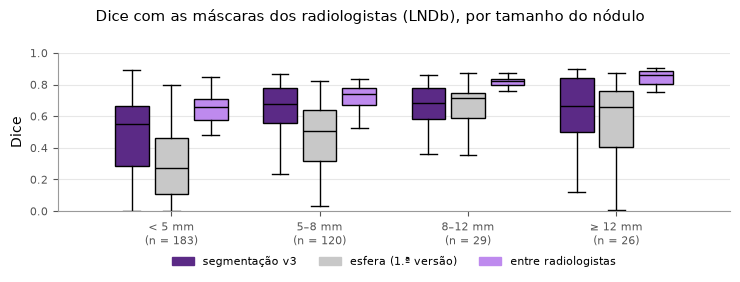

In [15]:
G.grafico_dice(DICE, cols_d)

> **Resultado:** nos nódulos pequenos (abaixo de 8 mm), a segmentação tem, em geral, um Dice mais alto do que a esfera, que apanha sobretudo pulmão e vasos: abaixo de 5 mm, a mediana é de cerca de 0,55, contra 0,27 da esfera, e entre 5 e 8 mm é de cerca de 0,68, contra 0,51. Ainda assim, isto não acontece em todos os nódulos, já que há casos em que a segmentação falha quase por completo (Dice perto de 0). A partir de 8 mm, as duas ficam próximas (medianas de cerca de 0,7 em ambas). Ao contrário do esperado, a segmentação não se aproxima mais do Dice entre radiologistas nos nódulos maiores: a diferença é pequena nos nódulos com menos de 8 mm, mas cresce a partir daí (cerca de 0,67 contra 0,86 nos nódulos com 12 mm ou mais). A principal fraqueza da segmentação é a variabilidade: as suas caixas são largas, sobretudo abaixo de 5 mm e acima de 12 mm (neste caso, metade dos nódulos fica entre cerca de 0,50 e 0,84), o que mostra que funciona bem em muitos nódulos, mas falha claramente em alguns. Já o Dice entre radiologistas é alto e estável em todas as faixas, embora só possa ser calculado nos nódulos com mais de um radiologista.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">13.2 Efeito de cada decisão</div>

Cada painel corresponde a uma decisão da secção 11 e mostra o S de cada modelo em cada opção, com o desvio entre repetições. A opção escolhida tem contorno preto. Quando as barras de erro de duas opções se sobrepõem muito, a diferença entre elas é da ordem do ruído, e é aí que a regra de um desvio prefere a opção mais simples.

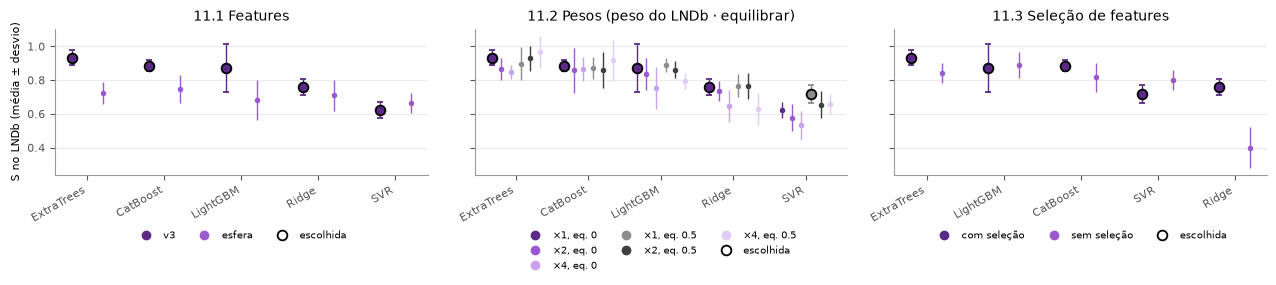

In [16]:
G.grafico_decisoes({"11.1 Features": (T_11, CONJUNTO, ["v3", "esfera"]),
                    "11.2 Pesos (peso do LNDb · equilibrar)": (T_12, ESC_PESOS, list(OPCOES_PESO)),
                    "11.3 Seleção de features": (T_13, SELECAO_TXT, ["com seleção", "sem seleção"])}, curto=CURTO_PESO)

> **Resultado:** a decisão com efeito mais claro é a das features (11.1). No Extra Trees e no CatBoost, a segmentação fica claramente acima da esfera, sem sobreposição das barras de erro; no LightGBM o ganho é grande mas as barras sobrepõem-se por causa da sua variância, enquanto na Ridge e no SVR as duas opções se sobrepõem, e no SVR a esfera fica até ligeiramente acima. Nos pesos (11.2), as opções de cada modelo sobrepõem-se em grande parte, o que confirma que as diferenças são sobretudo ruído e justifica a escolha da opção mais simples. A exceção é o SVR, em que ×1 com equilíbrio 0,5 se destaca das restantes. Nota-se também que dar mais peso ao LNDb tende a piorar a Ridge e o SVR. Na seleção de features (11.3), a versão com seleção é melhor no Extra Trees e no CatBoost e muito melhor na Ridge (cerca de 0,76 contra 0,40), enquanto no LightGBM e no SVR a versão sem seleção fica ligeiramente acima. As barras de erro são, no geral, pequenas, à exceção do LightGBM, cujo desvio chega a cerca de ±0,14, o que mostra que é o modelo cujos resultados mais variam com a divisão dos folds.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">13.3 Previsões contínuas e limiares</div>

Antes dos limiares, o modelo dá a cada nódulo um número contínuo, a sua estimativa da média das notas. O gráfico mostra esses valores agrupados pela nota real, com os limiares a tracejado: cada nódulo recebe a nota da faixa entre limiares onde cai. Num modelo perfeito, as caixas subiriam em escada e cada uma ficaria dentro da sua faixa. A sobreposição entre caixas vizinhas mostra quais notas o modelo tem mais dificuldade em separar.

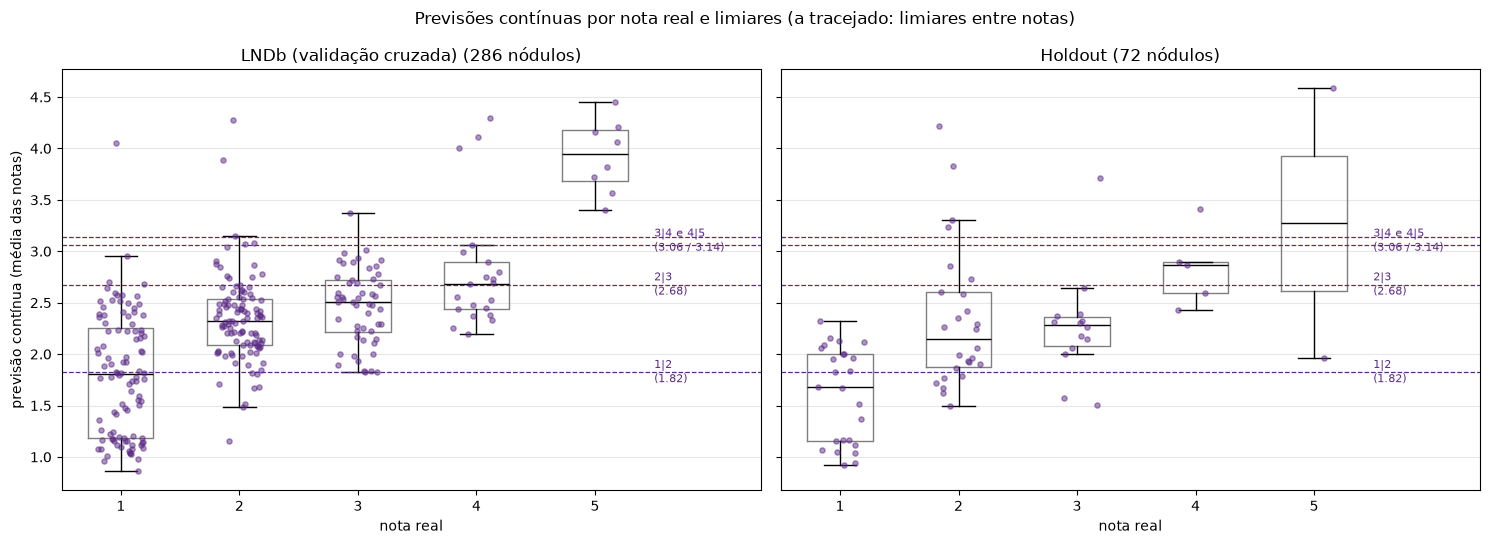

In [17]:
G.grafico_limiares([("LNDb (validação cruzada)", S_CAND[:, E_D].mean(0), Y_L), ("Holdout", s_h, y_h2)], LIMIARES)

> **Resultado:** as previsões sobem com a nota real, em escada, mas numa gama estreita. As notas 2, 3 e 4 ficam quase todas entre 2,2 e 2,9 e sobrepõem-se muito, enquanto as notas 1 e 5 se separam melhor (a nota 5 fica quase toda acima de 3,4). Os limiares otimizados ficam em 1,82, 2,68, 3,06 e 3,14: os limiares 3|4 e 4|5 estão muito próximos, pelo que a faixa da nota 4 tem apenas 0,08 de largura, o que explica que esta nota quase nunca seja prevista (recall de 0,03). Além disso, a maior parte dos nódulos de nota 3 e 4 fica abaixo do limiar 2|3, e por isso são muitas vezes classificados como nota 2. No holdout vê-se o mesmo, de forma ainda mais acentuada: os nódulos de nota 3 ficam praticamente todos abaixo do limiar 2|3 (cerca de 2,1 a 2,4), o que explica que 11 dos 14 sejam classificados como nota 2, e a nota 5 tem uma caixa muito larga, com parte dos nódulos abaixo dos limiares superiores.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">13.4 Erros do modelo final</div>

As matrizes de confusão mostram, para cada nota real, que notas o modelo previu: a cor indica a fração de cada nota real e os números são nódulos. Os erros junto à diagonal (uma nota de diferença) pesam pouco no QWK e no MAE, enquanto os mais afastados são os mais graves. O gráfico do recall resume quanto de cada nota é acertado, na validação cruzada (todas as repetições) e no holdout.

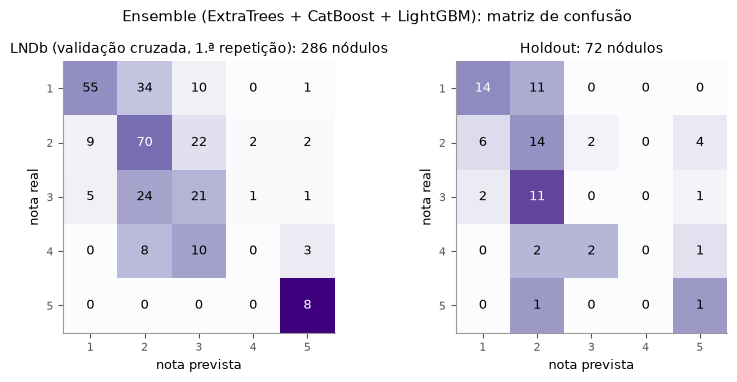

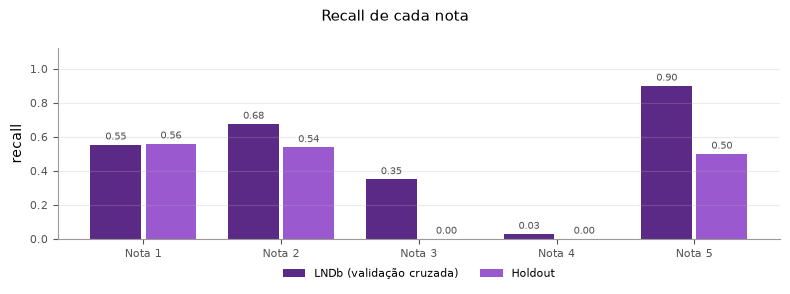

In [18]:
G.matrizes([("LNDb (validação cruzada, 1.ª repetição)", Y_L, pred_final[0]), ("Holdout", y_h2, pred_h2)],
           f"{CANDIDATO}: matriz de confusão")
G.grafico_recall({"LNDb (validação cruzada)": (np.tile(Y_L, len(pred_final)), pred_final.ravel()),
                  "Holdout": (y_h2, pred_h2)}, "Recall de cada nota")

> **Resultado:** a maioria dos erros é entre notas vizinhas (na 1.ª repetição da validação cruzada, 103 dos 132 erros), e a confusão entre os extremos é quase inexistente (apenas um nódulo de nota 1 previsto como 5), o que explica que o QWK seja razoável apesar de a balanced accuracy ser modesta. Na validação cruzada, o modelo acerta sobretudo nas notas extremas (recall de 0,55 na nota 1 e de 0,90 na nota 5) e na nota 2 (0,68), e tem mais dificuldade nas intermédias. A nota 2 funciona como um "íman": muitos nódulos de nota 1 (34) e de nota 3 (24) são previstos como nota 2. A nota 4 é a mais difícil (recall de 0,03): os seus nódulos espalham-se pelas notas 2, 3 e 5 e quase nunca são acertados, porque a faixa dos limiares desta nota é muito estreita. No holdout, o padrão é parecido, mas mais acentuado: as notas 3 e 4 nunca são acertadas (recall de 0), e a maioria dos nódulos de nota 3 é prevista como nota 2 (11 de 14). Os valores de recall variam muito, porque cada nota tem poucos nódulos: o recall de 0,50 na nota 5, por exemplo, corresponde a apenas um dos dois nódulos.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">13.5 Distribuição das notas previstas</div>

Um modelo bem calibrado nas classes deve prever cada nota com uma frequência parecida com a real. O gráfico compara a distribuição das notas reais do LNDb com a das notas previstas na validação cruzada, no holdout e no teste. No teste, que não tem notas, separam-se as lesões que parecem nódulos (sem recurso e com pelo menos 3 mm), porque as restantes tendem a receber notas baixas.

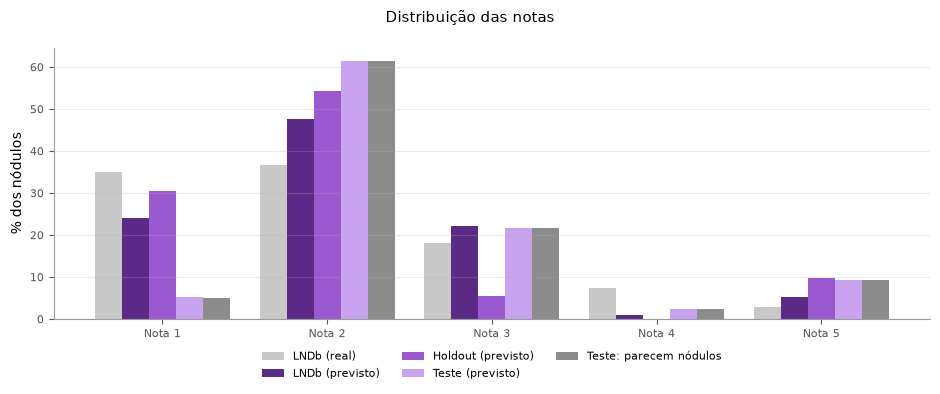

In [19]:
G.grafico_distribuicao({"LNDb (real)": Y_L, "LNDb (previsto)": pred_final[0], "Holdout (previsto)": pred_h2,
                        "Teste (previsto)": pred_te, "Teste: parecem nódulos": pred_te[parece_nodulo]})

> **Resultado:** na validação cruzada, a distribuição das notas previstas afasta-se um pouco da real do LNDb, porque os limiares otimizados não procuram reproduzir as proporções de cada nota: o modelo prevê mais notas 2 (48%, contra 37%) e menos notas 1 (24%, contra 35%), e a nota 4 quase desaparece (1%, contra 7%). No holdout, a tendência é parecida, com muitas notas 2 (54%) e quase nenhuma nota 3 (6%), mas a nota 1 continua frequente (31%). No teste, porém, o modelo prevê muito poucas notas 1 (5%, contra 35% no LNDb) e muitas notas 2 (62%), 3 (22%) e 5 (9%). Esta diferença é muito maior do que a observada na validação cruzada e no holdout, pelo que não se explica só pela tendência do modelo: ou as lesões do teste são de facto diferentes das do treino, ou o modelo subestima a nota 1 em dados novos. Como as duas distribuições do teste ("todos" e "parecem nódulos") são praticamente iguais, quase todas as lesões passam o filtro, e esse filtro não ajuda a explicar a diferença. Se o teste tiver uma distribuição parecida com a do LNDb, esta tendência vai prejudicar sobretudo o recall da nota 1.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">13.6 Validação cruzada, holdout e teto</div>

Este gráfico junta as três estimativas do desempenho do modelo final: a validação cruzada no LNDb (média ± desvio entre repetições, ligeiramente otimista), o holdout (com o intervalo de confiança de 95%) e o teto da concordância entre radiologistas (linha a tracejado). Se o valor da validação cruzada cair dentro do intervalo do holdout, as duas estimativas são compatíveis.A comparação com o teto mostra se o desempenho está ao nível de um radiologista.

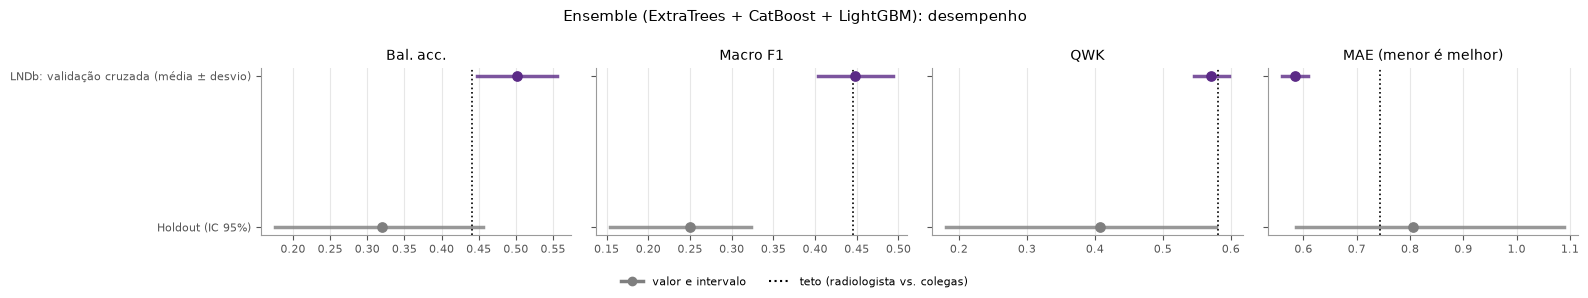

In [20]:
_v, _d = rep_final[M4].mean().to_numpy(), rep_final[M4].std().to_numpy()
G.grafico_intervalos({"LNDb: validação cruzada (média ± desvio)": (_v, _v - _d, _v + _d),
                      "Holdout (IC 95%)": IC_H}, f"{CANDIDATO}: desempenho", teto=TETO)

> **Resultado:** a validação cruzada e o holdout só são compatíveis no QWK, em que o valor da validação cruzada (0,571) cai dentro do intervalo do holdout (0,18 a 0,58). Na balanced accuracy e no macro F1, os valores da validação cruzada (0,502 e 0,448) ficam acima dos limites superiores dos intervalos do holdout (0,46 e 0,32), e no MAE o valor da validação cruzada (0,584) fica ligeiramente abaixo do limite inferior (0,59). O holdout indica, portanto, um desempenho pior do que a validação cruzada, e essa diferença não se explica só pelo tamanho reduzido da amostra. Ainda assim, os intervalos são muito largos, e a validação cruzada, com mais nódulos, continua a ser a estimativa mais estável. Comparada com o teto dos radiologistas, a validação cruzada fica ao seu nível: cerca de 0,06 acima na balanced accuracy, praticamente igual no macro F1 e no QWK, e com um MAE mais baixo (0,584, contra 0,745). No holdout, porém, o modelo fica abaixo do teto em todas as métricas.

<div style="text-align: left; color: #be8aee; font-family: 'Comic Sans MS', cursive, sans-serif; font-size: 25px;">13.7 Features mais importantes</div>

Por fim, a importância das features no primeiro membro do modelo baseado em árvores, treinado em todo o desenvolvimento, mostra em que informação o modelo se apoia. Espera-se que as medidas de tamanho (volume, diâmetros) dominem, por serem o fator mais ligado à malignidade, e é interessante ver se as features complementares da 9.4 (calcificação, espículas, margem) aparecem entre as mais importantes. Se o modelo escolhido não tiver nenhum membro baseado em árvores, esta célula não mostra nada.

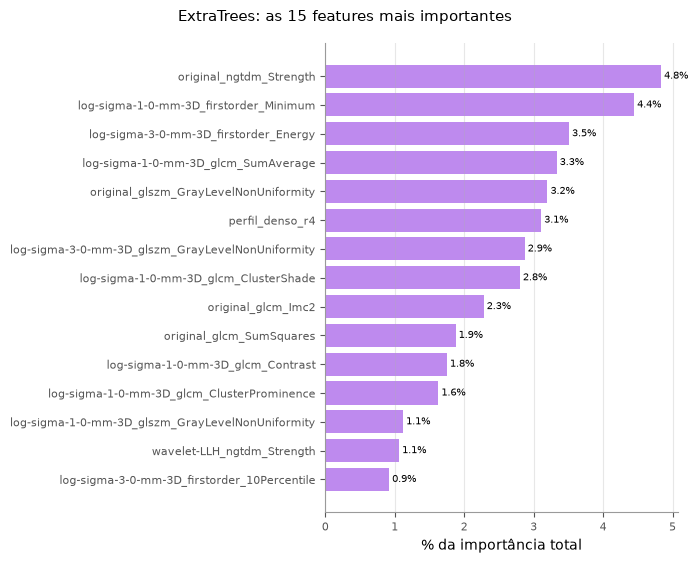

In [21]:
if IMP is not None:
    G.grafico_importancias(IMP, 15, f"{arvore}: as 15 features mais importantes")

> **Resultado:** a importância está muito mais distribuída do que se esperava: a feature mais importante, a Strength da NGTDM (4,8%), que mede o contraste entre cada voxel e a sua vizinhança, pesa menos de 5%, e as três primeiras somam apenas cerca de 13% do total (as 15 somam cerca de 39%). As medidas de forma explícitas (volume, diâmetros) não aparecem entre as 15 primeiras, provavelmente porque a seleção da 5.1 as retirou por estarem muito correlacionadas com outras features. O tamanho continua, no entanto, presente de forma indireta: a Energy da imagem filtrada com LoG (σ = 3 mm, 3,5%) é a soma das intensidades ao quadrado dentro da máscara, e as GrayLevelNonUniformity aumentam com o número de voxels, pelo que ambas crescem com o volume do nódulo. As restantes features descrevem sobretudo a intensidade e a textura (Minimum, SumAverage, ClusterShade, Contrast), e os filtros LoG dominam a lista (9 das 15). Das features complementares da 9.4, o perfil radial a 4 mm aparece em 6.º lugar (3,1%), o que mostra que a densidade à volta do nódulo acrescenta informação útil ao modelo.

<br>
<div style="text-align: center; color: #be8aee; font-family: 'Impact', sans-serif; font-size: 30px;">Conclusões (segunda versão)</div>
<br>

A principal melhoria desta segunda versão é a **segmentação do nódulo**. Face às máscaras dos radiologistas do LNDb, obtém um Dice mediano de 0,62, contra 0,41 da esfera da primeira versão e 0,73 entre radiologistas, e reduz as falhas graves de 26% para 13% (9.3). O ganho concentra-se nos nódulos com menos de 8 mm, que são a maioria, enquanto a partir de 8 mm a esfera fica ao mesmo nível. A segmentação é, no entanto, pouco consistente: funciona bem em muitos nódulos, mas falha claramente em alguns (13.1).

Das quatro mudanças, a que mais pesou foi a **troca da esfera pela segmentação**. Com tudo o resto igual, o S médio dos cinco modelos sobe de 0,706 para 0,814, sobretudo nos modelos de árvores (11.1). A **mudança de label** quase não teve efeito, porque só 1,4% das labels do LNDb mudam da mediana para a média (9.1). Os **pesos** do LNDb e o equilíbrio das classes não trouxeram melhoria acima do ruído, exceto no SVR (11.2). A **seleção de features** melhorou o S médio (0,833 contra 0,750), sobretudo na Ridge, e foi mantida (11.3). No fim, ficou um ensemble dos três modelos de árvores, com **limiares otimizados**, claramente melhores do que os quantis e do que arredondar simplesmente (11.4).

O desempenho esperado no LNDb é uma balanced accuracy de 0,502, um macro F1 de 0,448, um QWK de 0,571 e um MAE de 0,584 (11.4). No holdout, os valores são mais baixos (balanced accuracy de 0,320, macro F1 de 0,250, QWK de 0,408 e MAE de 0,806) e, na balanced accuracy e no macro F1, ficam fora do alcance da validação cruzada, o que indica que esta é algo otimista (13.6). Os erros são sobretudo entre notas vizinhas, e o modelo acerta principalmente nas notas 1, 2 e 5. As notas 3 e 4 são as mais difíceis: as previsões contínuas das notas 2 a 4 sobrepõem-se muito e tendem a ser classificadas como nota 2, e a faixa dos limiares da nota 4 é tão estreita que esta quase nunca é prevista (13.3 e 13.4). Face ao teto da concordância entre radiologistas (balanced accuracy de 0,441, QWK de 0,581), o modelo fica ao mesmo nível na validação cruzada, mas abaixo no holdout, o que mostra que a tarefa é difícil mesmo para especialistas. A importância das features está muito distribuída, com destaque para a textura nas imagens filtradas com LoG e para o perfil radial de densidade à volta do nódulo (13.7).

Estes resultados têm várias **limitações**. O LNDb tem poucos nódulos (286 fora do holdout e 72 no holdout), e muito poucos das notas 4 e 5, o que torna as estimativas instáveis (desvios entre repetições de até 0,14 no S) e o holdout pouco preciso. Há também 1146 features para tão poucos nódulos, com risco de sobreajuste, atenuado pela validação aninhada e pela regra de um desvio. No teste, o modelo prevê muito menos notas 1 do que existem no LNDb (5% contra 35%), o que pode prejudicar o resultado se as distribuições forem parecidas (13.5). Por fim, a segmentação foi desenhada a partir das falhas de uma versão anterior em nódulos do LNDb, e esta segunda versão foi construída depois de conhecido o resultado da primeira no teste, pelo que todas as estimativas podem ser ligeiramente otimistas.